<a href="https://colab.research.google.com/github/dung-ho03/capdyssey/blob/main/02_but_ppg_quality_cnn_%E1%84%87%E1%85%A9%E1%86%AB%E1%84%89%E1%85%B5%E1%86%AF%E1%84%92%E1%85%A2%E1%86%BC_%E1%84%89%E1%85%AE%E1%84%8C%E1%85%A5%E1%86%BC%E1%84%87%E1%85%A9%E1%86%AB11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BUT PPG 신호 품질 1D-CNN — 개발 · 평가 (Colab + Drive + GitHub) · 수정본 v3

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dung-ho03/capdyssey/blob/main/notebooks/02_but_ppg_quality_cnn.ipynb)

| 항목 | 내용 |
|---|---|
| 데이터 | BUT PPG v2.0.0 (PhysioNet, CC BY 4.0) — 50명, 10초 PPG 3,888개 |
| 입력 | PPG (스마트폰 영상 **빨간 채널** 기반), **10초 · 30Hz → 300개 값** |
| 정답 | `quality-hr-ann.csv` — **1 = 심박수 읽기 좋은 품질 / 0 = 나쁜 품질** (AF 정답 아님) |
| 연결 | 정답 CSV의 **ID** = PPG 파일의 ID (`{ID}/{ID}_PPG.dat/.hea`) |
| 분할 | **피험자 단위** (ID 앞 3자리 = 피험자) 5-fold 교차검증 → 누수 방지 |
| 주의 | 좋음 830 / 나쁨 3,058 → **모두 나쁨으로 예측해도 정확도 약 78.7%**. 정확도 대신 AUPRC·BalAcc·MCC·클래스별 지표를 봅니다. |

**실행 순서:** 0(Drive·GitHub·다운로드) → 1(설정) → 2(로드) → … 위에서 아래로.
처음 한 번은 `SMOKE_TEST = True` 로 빠르게 전체 흐름을 점검한 뒤 `False` 로 바꿔 **런타임 다시 시작 후 모두 실행**하세요.


### 본실행 결과에서 찾은 문제점 → 이번 수정 (v3)
| # | 본실행에서 보인 문제 | 근거(출력) | 수정 |
|---|---|---|---|
| 1 | **확률이 크게 부풀려져 있음** (`pos_weight` 효과) | Calibration 곡선이 대각선 아래: 예측 0.85 → 실제 좋음 비율 약 0.65 | val 로짓에 **Platt 보정** 후 임계값 결정. 보정 전/후 Brier·ECE 비교 출력 |
| 2 | **최종 임계값이 불안정** (0.768 vs CV 중앙값 0.664) | 최종 모델 val 이 피험자 몇 명뿐이라 F1 최대 지점이 흔들림 | 임계값을 **5-fold 임계값 중앙값**으로 고정, 두 값 모두 출력하고 OOF 성능 비교 |
| 3 | **표본 4개짜리 피험자의 AUROC 0.000** 이 '최악 피험자'로 표시됨 | 104·110 번 (n=4) | n < 20 피험자는 AUROC 해석 제외 표시, **피험자 전체 표 생략 없이 출력** |
| 4 | **복원 헤더 48개(피험자 100~111)가 다른 분포일 수 있음** (좋음 비율 높고 n 작음) | 정상 데이터와 좋음 비율·진폭이 다름 | 그룹별(복원/정상, 평평/비평평) 성능 표 + `EXCLUDE_HDR_FIXED` 로 **제외 재실행 옵션** |
| 5 | **추론 예시가 학습에 쓴 샘플** 로 만들어져 성능처럼 보임 | 예시 6개가 final 모델 학습 데이터 | 같은 샘플의 **OOF(검증에 쓰이지 않은) 예측**을 나란히 표시 |
| 6 | 결과를 **일부만** 볼 수 있음 (`head(8)`, 학습곡선·fold 상세·임계값표·신뢰구간 없음) | 요약 표만 출력 | 에폭별 로그, fold 상세 표(임계값·val/test 비율), fold별 혼동행렬, 학습곡선, 임계값 민감도 표, **피험자 부트스트랩 95% CI**, 모든 그림 PNG 저장, 마지막에 저장 결과 전체 출력 |
| 7 | 재현성 | DataLoader 셔플이 전역 RNG 의존 | `Generator` 시드 고정, cuDNN deterministic |
| 8 | Calibration 구간 경계 버그 (`p=1.0` 이 11번째 bin) | `np.digitize` 사용 | `clip` 으로 수정 |
| 9 | baseline 은 확률 보정 없이 임계값만 사용 | 비교가 비대칭 | baseline 도 동일하게 Platt 보정 + val 임계값 |

> 아래 "이전 수정본에서 고친 것" 은 앞 버전(헤더 파싱·캐시 등) 내역이며 그대로 유지됩니다.

### 이전 수정본에서 고친 것 (원인 → 수정)
1. **헤더가 깨진 레코드 48개(피험자 100~111)**: 헤더가 `300 신호 × 1 샘플`로 적혀 있어 wfdb 가 길이 1짜리 신호를 읽고, 이전 코드는 이를 `edge` 패딩으로 300개 **상수 신호**로 만들었음. 스모크 테스트가 하필 앞 12명(=이 48개)을 골라서 전부 상수 → 모델·baseline 모두 같은 확률(0.5421), AUROC 0.5.
   → `.hea` 를 직접 파싱해 두 형식을 모두 읽고, 예상 밖 형식은 **에러**로 멈춤 (조용한 패딩 제거).
2. **채널 선택**: `rec.sig_name` 이 깨져 있어 `PPG_R` 검색이 항상 실패 → 우연히 0번이 R 이었음. → 헤더 설명을 직접 읽어 `PPG_R` 을 **assert 로 확인**.
3. **캐시**: 예전 캐시(`but_ppg_300.npz`)에 쓰레기 데이터가 저장돼 있음 → 새 이름 `but_ppg_300_v2.npz` 사용.
4. **스모크 서브셋**: 앞 12명 → **무작위 12명 × 최대 24개**. `data`·`X_raw`·`y`·`groups` 가 항상 같은 샘플을 가리키도록 한 곳에서만 정함 (예전 Cell 20 삭제).
5. **NaN 은폐 제거**: `nan_to_num` 으로 덮지 않고 assert. 평평한 신호는 전처리에서 명시적으로 0 신호 처리.
6. **검증 분할**: val 에 좋음/나쁨이 모두 있도록 보장 (한쪽만 있으면 AUPRC·임계값이 무의미).
7. **스모크 BATCH**: 샘플이 적을 때 epoch 당 step 이 1번이던 문제 → 스모크는 BATCH=16.
8. **상수 출력 감지**: 예측이 거의 같은 값이면 assert 로 즉시 중단.
9. **저장 경로**: 스모크 결과는 `..._smoke` 폴더에 저장 (본 실행 결과를 덮어쓰지 않음).
10. 디버그 셀·중복 함수·`try/except + break` 제거. 어디서 실행해도 순서대로 돌아가도록 정리.

## 0. Google Drive · GitHub 연결 · 데이터 다운로드

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")

REPO_PARENT = "/content/drive/MyDrive/Colab Notebooks"
REPO_URL    = "https://github.com/dung-ho03/capdyssey.git"
REPO_DIR    = f"{REPO_PARENT}/capdyssey"
UPDATE_REPO = False          # True: git pull (로컬에서 수정한 파일과 충돌할 수 있어 기본은 끔)

if not os.path.isdir(f"{REPO_DIR}/.git"):
    os.makedirs(REPO_PARENT, exist_ok=True)
    !git clone {REPO_URL} "{REPO_DIR}"
elif UPDATE_REPO:
    !git -C "{REPO_DIR}" pull

os.chdir(REPO_DIR)
print("작업 폴더:", os.getcwd())

# torch / numpy / scipy / matplotlib 은 Colab 기본 설치본을 그대로 사용합니다.
!python -m pip install -q -r requirements.txt wfdb scikit-learn pandas

Mounted at /content/drive
작업 폴더: /content/drive/MyDrive/Colab Notebooks/capdyssey
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.2 MB/s eta 0:00:00


In [3]:
# BUT PPG 다운로드 (레포의 scripts/download_data.py 사용, 저장 위치: data/raw/but/)
# 최초 1회만 실행됩니다. 작은 파일이 약 2만 7천 개라 Drive에서는 시간이 걸립니다.
BUT_DIR = f"{REPO_DIR}/data/raw/but"
if not os.path.exists(f"{BUT_DIR}/download-status.json"):
    !python scripts/download_data.py but --plan
    !python scripts/download_data.py but --workers 8
else:
    print("이미 다운로드됨:", open(f"{BUT_DIR}/download-status.json").read())
assert os.path.isdir(BUT_DIR), "다운로드 실패: 위 출력의 에러 메시지를 확인하세요."

이미 다운로드됨: {
  "dataset": "but",
  "files_verified": 27125,
  "source": "https://physionet.org/content/butppg/2.0.0/",
  "license": "CC-BY-4.0"
}


## 1. 설정

In [4]:
import glob, json, random, time, re, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from scipy.signal import butter, filtfilt
from scipy.stats import skew, kurtosis
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (brier_score_loss, accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, matthews_corrcoef)
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
warnings.filterwarnings("ignore", message=".*The least populated class.*")
warnings.filterwarnings("ignore", message=".*A single label was found.*")

SMOKE_TEST        = False     # True: 무작위 12명(피험자당 최대 24개), 3 epoch → 흐름 점검용 / 본 실행은 False
SMOKE_SUBJECTS    = 12
SMOKE_PER_SUBJECT = 24
FS, N_SAMPLES = 30, 300       # 30Hz x 10초
CHANNEL_NAME  = "PPG_R"       # 헤더 설명에 이 이름이 있어야 함 (assert 로 확인)
N_FOLDS       = 5
BATCH, LR     = (16 if SMOKE_TEST else 64), 1e-3
EPOCHS        = 3 if SMOKE_TEST else 60
PATIENCE      = 10
SEED          = 42
FLAT_STD      = 1e-3          # 원본 표준편차가 이보다 작으면 '평평한 신호'
REBUILD_CACHE = False         # True: 캐시 무시하고 파일 다시 읽기
EXCLUDE_HDR_FIXED = False     # True: 헤더 복원 48개(피험자 100~111)를 빼고 실행 (민감도 분석용, 결과 폴더에 _nohdr 붙음)
VERBOSE_EPOCHS = True         # True: 에폭마다 loss / val 지표 출력
MIN_N_SUBJ_METRIC = 20        # 피험자별 AUROC 를 해석할 최소 표본 수
N_BOOT = 500                  # 피험자 단위 부트스트랩 반복 수 (CI)

CACHE_PATH = f"{REPO_DIR}/data/processed/but_ppg_300_v2.npz"      # v2: 예전 캐시(깨진 데이터)와 분리. .gitignore 대상(/data/processed/)
RESULT_DIR = f"{REPO_DIR}/models/but_quality_cnn_v1" + ("_smoke" if SMOKE_TEST else "") + ("_nohdr" if EXCLUDE_HDR_FIXED else "")
FIG_DIR    = f"{RESULT_DIR}/figures"; os.makedirs(FIG_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
pd.set_option("display.max_rows", None); pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
def show(name):                                  # 그림을 화면에 보여주고 PNG 로도 저장
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight"); plt.show()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| SMOKE_TEST =", SMOKE_TEST, "| BATCH =", BATCH, "| EPOCHS =", EPOCHS, "| EXCLUDE_HDR_FIXED =", EXCLUDE_HDR_FIXED)

device: cuda | SMOKE_TEST = False | BATCH = 64 | EPOCHS = 60 | EXCLUDE_HDR_FIXED = False


## 2. 데이터 로드 · ID 연결
- `quality-hr-ann.csv` 의 ID 와 같은 ID 의 `*_PPG` 파일을 연결합니다. (BOM·헤더 유무 자동 처리, ID는 6자리로 보정)
- **`.hea` 를 직접 파싱합니다.** (wfdb 는 이 데이터셋의 헤더 일부를 잘못 읽음)
  - 정상 형식(3,840개): `3채널(R,G,B) × 300샘플` → R 채널 사용
  - 깨진 형식(피험자 100~111, 48개): `300채널 × 1샘플`, `.dat` 은 전부 0 이고 **값이 헤더의 채널별 gain 에 들어 있음** → `-(0-baseline)/gain` 으로 복원 (0~255 픽셀 밝기 범위로 나와 정상 R 채널과 같은 단위)
  - 그 외 형식은 에러로 중단합니다. (조용한 패딩 없음)
- 한 번 읽은 신호는 Drive 의 `data/processed/but_ppg_300_v2.npz` 에 캐시합니다.
- 피험자 = `ID[:3]`

In [5]:
_SIG = re.compile(r"^\s*(\S+)\s+(\d+)\s+(-?[\d.eE+-]+)\((-?\d+)\)/(\S*)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s*(.*)$")

def read_one(item):
    """반환: (ID, 300개 값(R채널, 0~255 밝기), kind)  kind 0=정상 형식, 1=깨진 헤더 복원"""
    rid, base = item
    with open(base + ".hea", encoding="utf-8", errors="replace") as f:
        lines = [l.rstrip("\r\n") for l in f if l.strip() and not l.startswith("#")]
    h = lines[0].split(); n_sig, fs, n_samp = int(h[1]), float(h[2]), int(h[3])
    assert round(fs) == FS, f"{rid}: fs={fs}"
    sigs = [_SIG.match(l) for l in lines[1:1 + n_sig]]
    assert len(sigs) == n_sig and all(sigs), f"{rid}: 헤더 파싱 실패"
    gain = np.array([float(m[3]) for m in sigs]); bl = np.array([float(m[4]) for m in sigs])
    d = np.fromfile(base + ".dat", dtype="<i2")
    if n_sig == 3 and n_samp == N_SAMPLES:                       # 정상: 3채널 x 300샘플 (샘플 단위로 섞여 저장)
        assert sigs[0][11].strip().endswith(CHANNEL_NAME), f"{rid}: 0번 채널이 {CHANNEL_NAME} 이 아님: {sigs[0][11]!r}"
        assert d.size == n_sig * n_samp, f"{rid}: dat 크기 불일치"
        x = (d.reshape(n_samp, n_sig)[:, 0] - bl[0]) / gain[0]; kind = 0
    elif n_sig == N_SAMPLES and n_samp == 1:                     # 깨진 헤더(피험자 100~111)
        x = -((d.astype(np.float64) - bl) / gain); kind = 1
    else:
        raise ValueError(f"{rid}: 예상 못한 형식 n_sig={n_sig}, n_samp={n_samp}")
    assert len(x) == N_SAMPLES and np.isfinite(x).all(), f"{rid}: 길이/값 이상"
    return rid, x.astype(np.float32), kind

def build_dataset():
    ann = glob.glob(os.path.join(BUT_DIR, "**", "quality-hr-ann.csv"), recursive=True)
    assert ann, f"{BUT_DIR} 아래에 quality-hr-ann.csv 가 없습니다. 0번 셀의 다운로드 출력을 확인하세요."
    ann_path = ann[0]; base = os.path.dirname(ann_path); print("annotation:", ann_path)

    df = pd.read_csv(ann_path, header=None, encoding="utf-8-sig")        # 파일 맨 앞에 BOM 이 있음
    if not str(df.iloc[0, 0]).strip().isdigit():                          # 첫 행이 헤더면 제거
        df = df.iloc[1:]
    df = df.iloc[:, :3].copy(); df.columns = ["ID", "quality", "HR"]
    df["ID"] = df["ID"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.zfill(6)
    df["quality"] = df["quality"].astype(int); df["HR"] = pd.to_numeric(df["HR"], errors="coerce")
    assert not df["ID"].duplicated().any(), "CSV 에 중복 ID 가 있습니다."

    index = {}                                                            # ID -> *_PPG 경로(확장자 제외)
    for dirpath, _, files in os.walk(base):
        for f in files:
            if f.endswith("_PPG.hea"): index[f[:-8]] = os.path.join(dirpath, f[:-4])
    print(f"CSV {len(df)}개 / PPG 파일 {len(index)}개")
    todo = [(rid, index[rid]) for rid in df["ID"] if rid in index]
    missing = [rid for rid in df["ID"] if rid not in index]
    print(f"PPG 없는 ID: {len(missing)}개", missing[:10])
    assert todo, "CSV 의 ID 와 매칭되는 PPG 파일이 없습니다."

    t0 = time.time()
    with ThreadPoolExecutor(8) as pool: out = list(pool.map(read_one, todo))
    kinds = np.array([o[2] for o in out])
    print(f"읽기 완료 {time.time()-t0:.0f}s | 정상 형식 {int((kinds==0).sum())}개, 깨진 헤더 복원 {int((kinds==1).sum())}개")
    got = {o[0]: o[1] for o in out}; kind_of = {o[0]: o[2] for o in out}
    df = df[df["ID"].isin(got)].reset_index(drop=True)
    df["hdr_fixed"] = [kind_of[r] for r in df["ID"]]
    X_raw = np.stack([got[r] for r in df["ID"]])
    return df, X_raw

def load_but():
    if os.path.exists(CACHE_PATH) and not REBUILD_CACHE:
        z = np.load(CACHE_PATH, allow_pickle=False); print("캐시 사용:", CACHE_PATH)
        return pd.DataFrame({"ID": z["ids"], "quality": z["y"], "HR": z["hr"], "hdr_fixed": z["kind"]}), z["X_raw"]
    df, X_raw = build_dataset()
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    np.savez_compressed(CACHE_PATH, ids=np.asarray(df["ID"].tolist(), dtype="U8"), y=df["quality"].to_numpy(dtype=np.int64),
                        hr=df["HR"].to_numpy(dtype=np.float64), kind=df["hdr_fixed"].to_numpy(dtype=np.int64), X_raw=X_raw.astype(np.float32))
    print("캐시 저장:", CACHE_PATH); return df, X_raw

data, X_raw = load_but()
data["subject"] = data["ID"].str[:3]
assert len(data) == len(X_raw) == 3888 and X_raw.shape[1] == N_SAMPLES, f"예상(3888, 300)과 다름: {X_raw.shape}"
assert np.isfinite(X_raw).all()

if SMOKE_TEST:      # 무작위 피험자 + 피험자당 최대 N개. data / X_raw 는 여기서 '한 번만' 줄입니다.
    rng = np.random.default_rng(SEED)
    keep = rng.choice(sorted(data["subject"].unique()), SMOKE_SUBJECTS, replace=False)
    idx = []
    for s in keep:
        ii = np.where(data["subject"].values == s)[0]
        idx += list(rng.choice(ii, min(len(ii), SMOKE_PER_SUBJECT), replace=False))
    idx = np.sort(idx)
    data, X_raw = data.iloc[idx].reset_index(drop=True), X_raw[idx]

if EXCLUDE_HDR_FIXED:   # 복원한 헤더 샘플 제외 (민감도 분석)
    keepm = data["hdr_fixed"].values == 0
    print(f"EXCLUDE_HDR_FIXED: 복원 헤더 {int((~keepm).sum())}개 제외")
    data, X_raw = data[keepm].reset_index(drop=True), X_raw[keepm]

y = data["quality"].values.astype(int); groups = data["subject"].values
assert len(data) == len(X_raw) == len(y) == len(groups)
print(f"samples={len(data)} subjects={len(set(groups))} | 좋음(1)={y.sum()} 나쁨(0)={(y==0).sum()} ({y.mean():.1%} good) | X_raw={X_raw.shape}")
print(f"참고) 모두 '나쁨'으로 예측했을 때 정확도 = {(y==0).mean():.3f}")
print(f"복원한 깨진 헤더 샘플: {int(data['hdr_fixed'].sum())}개 | 원본 값 범위: {X_raw.min():.1f} ~ {X_raw.max():.1f} (0~255 이면 정상)")

캐시 사용: /content/drive/MyDrive/Colab Notebooks/capdyssey/data/processed/but_ppg_300_v2.npz
samples=3888 subjects=50 | 좋음(1)=830 나쁨(0)=3058 (21.3% good) | X_raw=(3888, 300)
참고) 모두 '나쁨'으로 예측했을 때 정확도 = 0.787
복원한 깨진 헤더 샘플: 48개 | 원본 값 범위: 0.0 ~ 255.0 (0~255 이면 정상)


## 3. 데이터 확인 · 전처리 (0.5–5Hz 밴드패스 → 샘플별 z-score)
- 평평한(포화·가림) 신호는 z-score 를 하면 노이즈가 증폭되므로 **명시적으로 0 신호**로 둡니다.
- 아래 표에서 `flat` 과 라벨의 관계를 확인하세요. 평평한 신호는 대부분 '나쁨'이라, 모델이 이것만 맞혀도 점수가 올라갑니다.

             n  good_ratio
count   50.000      50.000
mean    77.760       0.333
std     44.334       0.291
min      4.000       0.009
25%     54.000       0.095
50%    108.000       0.231
75%    108.000       0.632
max    108.000       1.000

평평한 신호: 122 / 3888  (라벨 분포: 나쁨 119, 좋음 3)
전부 0 인 입력 행: 122 → 평평한 신호 수와 같아야 정상
원본 표준편차(진폭) 평균 — 나쁨: 7.24 | 좋음: 2.39

[피험자별 샘플 수 · 좋음 비율 — 전체]


subject,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149
n,4.00,4.00,4.0,4.0,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.0,108.000,54.000,108.000,108.00,108.000,108.000,54.000,96.000,54.000,96.00,108.000,108.000,108.00,108.00,96.00,108.000,108.000,108.000,108.000,108.000,108.000,108.000,108.000,108.000,108.000,108.000,54.000,108.00,108.00,108.000,108.000,108.000,108.000,96.000,108.000,108.000,108.000,108.000
good_ratio,0.75,0.75,1.0,0.5,0.75,0.75,0.75,0.75,0.75,0.75,0.75,0.5,0.019,0.037,0.083,0.13,0.009,0.028,0.093,0.104,0.204,0.01,0.046,0.102,0.12,0.37,0.25,0.148,0.019,0.028,0.083,0.241,0.231,0.667,0.037,0.583,0.454,0.176,0.648,0.25,0.75,0.157,0.102,0.176,0.231,0.146,0.333,0.231,0.056,0.556


[복원 헤더(1) vs 정상(0) — 분포가 크게 다르면 모델이 '형식'을 배울 위험]


,n,good_ratio,raw_mean,raw_std_median,flat
hdr_fixed,,,,,
0,3840,0.207,167.093994,2.101,122
1,48,0.729,213.061996,0.344,0


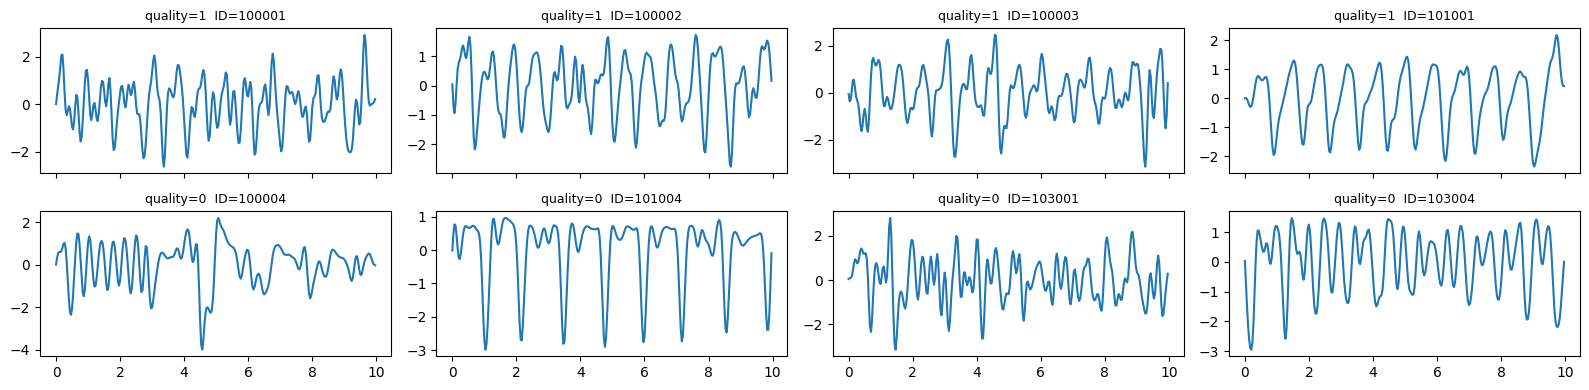

In [6]:
sub = data.groupby("subject")["quality"].agg(n="size", good_ratio="mean")
print(sub.describe().round(3))

b, a = butter(3, [0.5/(FS/2), 5.0/(FS/2)], btype="band")
def preprocess(x):
    x = np.asarray(x, dtype=np.float64)
    if x.std() < FLAT_STD:                      # 평평한 신호 → 0 신호
        return np.zeros(len(x), dtype=np.float32)
    x = filtfilt(b, a, x - x.mean())
    return ((x - x.mean()) / (x.std() + 1e-8)).astype(np.float32)

raw_std = X_raw.std(1)
flat = raw_std < FLAT_STD
X = np.stack([preprocess(x) for x in X_raw])[:, None, :]      # (N, 1, 300)
assert np.isfinite(X).all(), "전처리 후 NaN/inf 가 있습니다."
print(f"\n평평한 신호: {int(flat.sum())} / {len(flat)}  (라벨 분포: 나쁨 {int((y[flat]==0).sum())}, 좋음 {int((y[flat]==1).sum())})")
print("전부 0 인 입력 행:", int((np.abs(X).sum((1, 2)) == 0).sum()), "→ 평평한 신호 수와 같아야 정상")
print("원본 표준편차(진폭) 평균 — 나쁨: %.2f | 좋음: %.2f" % (raw_std[y == 0].mean(), raw_std[y == 1].mean()))
assert (~flat).sum() > 0.5 * len(flat), "대부분의 신호가 평평합니다. 데이터 읽기를 다시 확인하세요."

hdr = data["hdr_fixed"].values.astype(int)
print("\n[피험자별 샘플 수 · 좋음 비율 — 전체]"); display(sub.round(3).T)
g_ = pd.DataFrame({"hdr_fixed": hdr, "good": y, "raw_mean": X_raw.mean(1), "raw_std": raw_std, "flat": flat})
print("[복원 헤더(1) vs 정상(0) — 분포가 크게 다르면 모델이 '형식'을 배울 위험]")
display(g_.groupby("hdr_fixed").agg(n=("good", "size"), good_ratio=("good", "mean"), raw_mean=("raw_mean", "mean"),
                                   raw_std_median=("raw_std", "median"), flat=("flat", "sum")).round(3))

t = np.arange(N_SAMPLES) / FS
fig, ax = plt.subplots(2, 4, figsize=(16, 4), sharex=True)
for r, lab in enumerate([1, 0]):
    cand = [i for i in np.where(y == lab)[0] if not flat[i]][:4]
    for c, i in enumerate(cand):
        ax[r, c].plot(t, X[i, 0]); ax[r, c].set_title(f"quality={lab}  ID={data['ID'][i]}", fontsize=9)
show("01_examples")

## 4. 모델 · 학습 함수

In [7]:
class Block(nn.Module):
    def __init__(self, cin, cout, k=5, p=0.15):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(cin, cout, k, padding=k//2), nn.BatchNorm1d(cout), nn.ReLU(),
                                 nn.Conv1d(cout, cout, k, padding=k//2), nn.BatchNorm1d(cout), nn.ReLU(),
                                 nn.MaxPool1d(2), nn.Dropout(p))
    def forward(self, x): return self.net(x)

class PPGQualityCNN(nn.Module):                # 입력 (B,1,300) → '좋은 품질' 로짓
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(Block(1, 16), Block(16, 32), Block(32, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, x): return self.head(self.features(x)).squeeze(-1)

def make_loader(idx, shuffle=False, seed=SEED):
    ds = TensorDataset(torch.from_numpy(X[idx]), torch.from_numpy(y[idx].astype(np.float32)))
    g = torch.Generator(); g.manual_seed(seed)                       # 셔플 순서도 재현 가능하게
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=bool(shuffle and len(idx) > BATCH), generator=g if shuffle else None)

@torch.no_grad()
def predict_logit(model, idx):
    model.eval(); out = []
    for xb, _ in make_loader(idx):
        out.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(out).astype(np.float64)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64)))
def predict(model, idx): return sigmoid(predict_logit(model, idx))

# --- 확률 보정(Platt): pos_weight 로 부풀려진 확률을 실제 비율에 맞춤. 순서는 바뀌지 않음(AUROC/AUPRC 동일) ---
def fit_platt(score, y_true):
    cal = LogisticRegression(C=1e4, max_iter=1000).fit(np.asarray(score, dtype=np.float64).reshape(-1, 1), y_true)
    assert cal.coef_[0, 0] > 0, "Platt 기울기가 음수: 점수와 라벨이 반대로 움직입니다."
    return cal
def apply_platt(cal, score): return cal.predict_proba(np.asarray(score, dtype=np.float64).reshape(-1, 1))[:, 1]

def best_threshold(y_true, p):                 # val 에서 '좋음' 클래스 F1 최대 지점
    assert len(set(y_true)) == 2, "val 에 한 클래스만 있어 임계값을 정할 수 없습니다."
    pr, rc, th = precision_recall_curve(y_true, p); f1 = 2*pr*rc/(pr+rc+1e-9)
    return float(th[np.argmax(f1[:-1])])

def split_train_val(idx, n_splits, seed):
    """idx 안에서 피험자 단위로 train/val 분리. val·train 모두 좋음/나쁨이 있는 분할만 사용."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for a, b_ in sgkf.split(idx, y[idx], groups[idx]):
        if len(set(y[idx][b_])) == 2 and len(set(y[idx][a])) == 2:
            return idx[a], idx[b_]
    raise RuntimeError("좋음/나쁨이 모두 있는 val 분할을 찾지 못했습니다. 데이터 양을 늘리거나 n_splits 를 줄이세요.")

def train_one(tr_idx, va_idx, tag=""):
    torch.manual_seed(SEED)
    model = PPGQualityCNN().to(device)
    pos_w = torch.tensor((1 - y[tr_idx].mean()) / max(y[tr_idx].mean(), 1e-6), device=device, dtype=torch.float32)   # 불균형 보정
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=4)
    dl = make_loader(tr_idx, True); best, wait, best_state, best_ep = -1.0, 0, None, 0
    hist = {"train_loss": [], "val_auprc": [], "val_auroc": [], "lr": []}
    for ep in range(EPOCHS):
        model.train(); tot = 0.0; seen = 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            xb = xb + 0.02 * torch.randn_like(xb)                  # 가벼운 노이즈 증강
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(xb); seen += len(xb)
        pv = predict(model, va_idx)
        ap, auc = average_precision_score(y[va_idx], pv), roc_auc_score(y[va_idx], pv); sched.step(ap)
        hist["train_loss"].append(float(tot / max(seen, 1))); hist["val_auprc"].append(float(ap)); hist["val_auroc"].append(float(auc))
        hist["lr"].append(float(opt.param_groups[0]["lr"]))
        improved = ap > best
        if improved: best, wait, best_ep, best_state = ap, 0, ep + 1, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else: wait += 1
        if VERBOSE_EPOCHS:
            print(f"{tag} ep{ep+1:02d} loss={hist['train_loss'][-1]:.4f} val_AUPRC={ap:.4f} val_AUROC={auc:.4f} lr={hist['lr'][-1]:.1e}{'  *best' if improved else ''}")
        if wait >= PATIENCE: break
    if best_state is not None: model.load_state_dict(best_state)
    hist.update(best_epoch=int(best_ep), epochs_run=int(ep + 1), best_val_auprc=float(best))
    print(f"{tag} epochs={ep+1} (best ep={best_ep}) best val AUPRC={best:.4f}")
    return model, hist

## 5. 5-fold 피험자 단위 교차검증
- 각 fold에서 test 피험자는 학습·검증에 전혀 쓰이지 않습니다. (assert 로 확인)
- train 피험자 중 약 20%를 val 로 떼어 early stopping 과 **임계값(F1 최대)** 을 정하고, 그 임계값을 test 에 그대로 적용합니다.
- **확률 보정**: 각 fold 의 val 로짓으로 Platt 보정을 학습하고, 보정된 확률에서 임계값(F1 최대)을 정합니다. baseline 도 똑같이 처리합니다.
- 비교용 baseline: 단순 통계 특징 6개 + **신호 진폭(log 표준편차)** + 로지스틱 회귀 (같은 분할). CNN 은 z-score 로 진폭을 못 보므로, baseline 이 진폭을 보는 쪽이 더 엄격한 비교입니다.
- **스모크 테스트(SMOKE_TEST=True) 결과 숫자는 해석하지 마세요.** 흐름이 에러 없이 도는지만 보는 용도입니다.

In [8]:
def baseline_features(x, raw):                 # x: 전처리된 1D 신호, raw: 원본 1D 신호
    amp = np.log1p(raw.std())
    if x.std() < 1e-8:                         # 평평한 신호: 형태 특징은 0, 진폭만 사용
        return [0.0] * 6 + [amp]
    f = np.abs(np.fft.rfft(x))**2; fr = np.fft.rfftfreq(len(x), 1/FS)
    band = (fr >= 0.7) & (fr <= 3.5)
    ac = np.correlate(x, x, "full")[len(x)-1:]; ac = ac / (ac[0] + 1e-12)
    return [skew(x), kurtosis(x), f[band].max()/(f.sum()+1e-9), f[band].sum()/(f.sum()+1e-9), ac[8:45].max(), np.abs(np.diff(x)).mean(), amp]

F = np.array([baseline_features(X[i, 0], X_raw[i]) for i in range(len(X))], dtype=np.float64)
assert np.isfinite(F).all(), f"baseline 특징에 NaN/inf 가 {int((~np.isfinite(F)).sum())}개 있습니다."
print("X:", X.shape, "| F:", F.shape, "| 좋음 비율: %.3f" % y.mean(), "| 피험자:", len(set(groups)), "| F 고유 행 수:", len(np.unique(F.round(6), axis=0)))

n_folds = min(N_FOLDS, len(set(groups)))
skf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
p_raw = np.zeros(len(y)); p_cnn = np.zeros(len(y)); p_base = np.zeros(len(y)); thr_cnn = np.zeros(len(y)); thr_base = np.zeros(len(y)); fold_id = np.full(len(y), -1)
split_info, histories, fold_states, fold_rows = {}, {}, {}, []

for k, (trval, te) in enumerate(skf.split(X, y, groups)):
    tr, va = split_train_val(trval, 5, SEED + k)
    assert not (set(groups[trval]) & set(groups[te])) and not (set(groups[tr]) & set(groups[va]))
    print(f"\n[fold {k}] train={len(tr)} val={len(va)} test={len(te)} | test subjects={len(set(groups[te]))} | val good={y[va].mean():.2f} test good={y[te].mean():.2f}")
    model, histories[k] = train_one(tr, va, f"[fold {k}]")
    lg_va, lg_te = predict_logit(model, va), predict_logit(model, te)
    cal = fit_platt(lg_va, y[va])
    p_raw[te] = sigmoid(lg_te); p_cnn[te] = apply_platt(cal, lg_te); thr_cnn[te] = best_threshold(y[va], apply_platt(cal, lg_va))
    clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(F[tr], y[tr])
    sb_va, sb_te = clf.decision_function(F[va]), clf.decision_function(F[te]); calb = fit_platt(sb_va, y[va])
    p_base[te] = apply_platt(calb, sb_te); thr_base[te] = best_threshold(y[va], apply_platt(calb, sb_va))
    fold_id[te] = k
    fold_states[k] = {kk: v.detach().cpu().clone() for kk, v in model.state_dict().items()}
    if p_cnn[te].std() < 1e-4: print(f"  ⚠ fold {k}: CNN 예측이 거의 상수입니다 (std={p_cnn[te].std():.2e})")
    split_info[f"fold{k}"] = {"train_subjects": sorted(set(groups[tr])), "val_subjects": sorted(set(groups[va])), "test_subjects": sorted(set(groups[te]))}
    h = histories[k]
    fold_rows.append({"fold": k, "n_train": len(tr), "n_val": len(va), "n_test": len(te), "test_subjects": len(set(groups[te])),
                      "val_good": y[va].mean(), "test_good": y[te].mean(), "epochs_run": h["epochs_run"], "best_epoch": h["best_epoch"],
                      "val_AUPRC(raw)": h["best_val_auprc"], "thr_cnn": thr_cnn[te][0], "thr_base": thr_base[te][0],
                      "platt_slope": float(cal.coef_[0, 0]), "platt_intercept": float(cal.intercept_[0])})

assert (fold_id >= 0).all(), "일부 샘플이 어떤 fold 의 test 에도 들어가지 않았습니다."
assert p_cnn.std() > 1e-4 and p_base.std() > 1e-4, "예측이 상수입니다. 입력 데이터/학습을 다시 확인하세요."
fold_table = pd.DataFrame(fold_rows).set_index("fold")
print("\n[fold 상세] — val_AUPRC 가 낮고 val_good 이 작은 fold 는 임계값이 불안정할 수 있음"); display(fold_table.round(4))
print("끝난 fold:", list(split_info.keys()), "→ 모두 완료, 평가 셀을 실행하세요.")

X: (3888, 1, 300) | F: (3888, 7) | 좋음 비율: 0.213 | 피험자: 50 | F 고유 행 수: 3874

[fold 0] train=2742 val=648 test=498 | test subjects=8 | val good=0.18 test good=0.17
[fold 0] ep01 loss=0.8361 val_AUPRC=0.4328 val_AUROC=0.7735 lr=1.0e-03  *best
[fold 0] ep02 loss=0.7020 val_AUPRC=0.4262 val_AUROC=0.7800 lr=1.0e-03
[fold 0] ep03 loss=0.6581 val_AUPRC=0.4353 val_AUROC=0.7877 lr=1.0e-03  *best
[fold 0] ep04 loss=0.6630 val_AUPRC=0.4076 val_AUROC=0.7899 lr=1.0e-03
[fold 0] ep05 loss=0.6210 val_AUPRC=0.4066 val_AUROC=0.7896 lr=1.0e-03
[fold 0] ep06 loss=0.6170 val_AUPRC=0.4676 val_AUROC=0.8210 lr=1.0e-03  *best
[fold 0] ep07 loss=0.6139 val_AUPRC=0.3260 val_AUROC=0.7439 lr=1.0e-03
[fold 0] ep08 loss=0.6290 val_AUPRC=0.4550 val_AUROC=0.8131 lr=1.0e-03
[fold 0] ep09 loss=0.5947 val_AUPRC=0.4441 val_AUROC=0.8075 lr=1.0e-03
[fold 0] ep10 loss=0.5861 val_AUPRC=0.4667 val_AUROC=0.8165 lr=1.0e-03
[fold 0] ep11 loss=0.5884 val_AUPRC=0.3343 val_AUROC=0.7313 lr=5.0e-04
[fold 0] ep12 loss=0.5882 val_AUPRC=

,n_train,n_val,n_test,test_subjects,val_good,test_good,epochs_run,best_epoch,val_AUPRC(raw),thr_cnn,thr_base,platt_slope,platt_intercept
fold,,,,,,,,,,,,,
0,2742,648,498,8,0.1775,0.1747,16,6,0.4676,0.3248,0.3759,0.7488,-1.5778
1,2538,278,1072,12,0.1906,0.2099,16,6,0.8400,0.5062,0.2782,1.3122,-0.5054
2,2862,440,586,7,0.2818,0.2014,12,2,0.8943,0.4345,0.3242,2.0897,-2.3653
3,2156,848,884,13,0.2618,0.2839,19,9,0.6957,0.3411,0.4039,1.1076,-2.1961
4,2442,598,848,10,0.1204,0.1757,22,12,0.5208,0.1478,0.1598,0.8751,-1.4692


끝난 fold: ['fold0', 'fold1', 'fold2', 'fold3', 'fold4'] → 모두 완료, 평가 셀을 실행하세요.


## 6. 평가

In [9]:
def ece(y_true, p, bins=10):
    bi = np.clip((np.asarray(p) * bins).astype(int), 0, bins - 1); e = 0.0
    for c in range(bins):
        m = bi == c
        if m.any(): e += m.mean() * abs(p[m].mean() - y_true[m].mean())
    return float(e)

def metrics(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    two = len(set(y_true)) == 2
    return {"AUROC": roc_auc_score(y_true, p) if two else np.nan, "AUPRC": average_precision_score(y_true, p) if two else np.nan,
            "Acc": accuracy_score(y_true, pred), "BalAcc": balanced_accuracy_score(y_true, pred),
            "Precision(good)": pr, "Recall(good)": rc, "F1(good)": f1,
            "Specificity(bad 걸러냄)": tn/(tn+fp+1e-9), "MCC": matthews_corrcoef(y_true, pred),
            "Brier": brier_score_loss(y_true, p), "ECE": ece(y_true, p), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

print(f"(참고: 항상 '나쁨' 예측 정확도 {(y==0).mean():.3f}, AUPRC 기준선 = 좋음 비율 {y.mean():.3f})")
if SMOKE_TEST: print("※ SMOKE_TEST 결과: 흐름 점검용이므로 숫자를 해석하지 마세요.")
summary = pd.DataFrame({"1D-CNN": metrics(y, p_cnn, thr_cnn), "Baseline(LogReg+진폭)": metrics(y, p_base, thr_base)})
print("\n[전체 OOF 성능 — 모든 fold 의 test 예측을 합침 (fold 별 임계값 적용)]"); display(summary.round(4))

print("\n[확률 보정 효과 — CNN]  (낮을수록 좋음)")
display(pd.DataFrame({"보정 전(sigmoid)": {"Brier": brier_score_loss(y, p_raw), "ECE": ece(y, p_raw), "평균 예측확률": p_raw.mean()},
                      "보정 후(Platt)":  {"Brier": brier_score_loss(y, p_cnn), "ECE": ece(y, p_cnn), "평균 예측확률": p_cnn.mean()},
                      "실제 좋음 비율":   {"Brier": np.nan, "ECE": np.nan, "평균 예측확률": y.mean()}}).round(4))

def per_fold(p, thr):
    rows = []
    for k in range(n_folds):
        m = fold_id == k; r = metrics(y[m], p[m], thr[m]); r["fold"] = k; rows.append(r)
    return pd.DataFrame(rows).set_index("fold")
cv, cv_base = per_fold(p_cnn, thr_cnn), per_fold(p_base, thr_base)
print("\n[fold 별 — 1D-CNN]"); display(cv.round(4))
print("[fold 별 — Baseline]"); display(cv_base.round(4))
keys = ["AUROC", "AUPRC", "BalAcc", "F1(good)", "MCC"]
fold_agg = pd.concat({"CNN": cv[keys].agg(["mean", "std"]), "Baseline": cv_base[keys].agg(["mean", "std"])}).round(4)
print("[fold 평균 ± 표준편차]"); display(fold_agg)

# 피험자 단위 부트스트랩 95% CI (같은 피험자는 통째로 뽑음)
def boot_ci(n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); subs = sorted(set(groups)); idx_of = {s_: np.where(groups == s_)[0] for s_ in subs}; res = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_of[subs[j]] for j in rng.choice(len(subs), len(subs), replace=True)])
        if len(set(y[ii])) < 2: continue
        mc, mb = metrics(y[ii], p_cnn[ii], thr_cnn[ii]), metrics(y[ii], p_base[ii], thr_base[ii])
        res.append({**{f"CNN {k_}": mc[k_] for k_ in keys}, **{f"Base {k_}": mb[k_] for k_ in keys}, **{f"Δ(CNN-Base) {k_}": mc[k_] - mb[k_] for k_ in keys}})
    r = pd.DataFrame(res); mc0, mb0 = summary["1D-CNN"], summary["Baseline(LogReg+진폭)"]
    pt = {**{f"CNN {k_}": mc0[k_] for k_ in keys}, **{f"Base {k_}": mb0[k_] for k_ in keys}, **{f"Δ(CNN-Base) {k_}": mc0[k_] - mb0[k_] for k_ in keys}}
    return pd.DataFrame({"point": pd.Series(pt), "ci_2.5%": r.quantile(0.025), "ci_97.5%": r.quantile(0.975)}).round(4), len(r)
ci, n_ok = boot_ci()
print(f"\n[피험자 단위 부트스트랩 95% CI — {n_ok}회]  Δ 의 구간이 0 을 포함하면 CNN 우위가 불확실"); display(ci)

# 임계값 민감도 (보정된 확률 기준, 모든 fold 에 같은 임계값)
thr_rows = []
for th in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    m_ = metrics(y, p_cnn, np.full(len(y), th)); m_["thr"] = th; thr_rows.append(m_)
thr_table = pd.DataFrame(thr_rows).set_index("thr")[["Precision(good)", "Recall(good)", "F1(good)", "Specificity(bad 걸러냄)", "BalAcc", "MCC", "TP", "FP", "FN", "TN"]]
print("\n[임계값 민감도 — CNN]"); display(thr_table.round(3))

(참고: 항상 '나쁨' 예측 정확도 0.787, AUPRC 기준선 = 좋음 비율 0.213)

[전체 OOF 성능 — 모든 fold 의 test 예측을 합침 (fold 별 임계값 적용)]


,1D-CNN,Baseline(LogReg+진폭)
AUROC,0.8575,0.7601
AUPRC,0.6219,0.5259
Acc,0.8392,0.7683
BalAcc,0.7898,0.6714
Precision(good),0.6064,0.4608
Recall(good),0.7036,0.5024
F1(good),0.6514,0.4807
Specificity(bad 걸러냄),0.8761,0.8404
MCC,0.5503,0.3324
Brier,0.1128,0.1381



[확률 보정 효과 — CNN]  (낮을수록 좋음)


,보정 전(sigmoid),보정 후(Platt),실제 좋음 비율
Brier,0.1653,0.1128,NaN
ECE,0.1877,0.0358,NaN
평균 예측확률,0.4011,0.2151,0.2135



[fold 별 — 1D-CNN]


...

AUROC   AUPRC  BalAcc  F1(good)     MCC
CNN      mean  0.8647  0.6346  0.7874    0.6366  0.5407
         std   0.0121  0.1063  0.0390    0.0768  0.0775
Baseline mean  0.7470  0.5091  0.6558    0.4431  0.3145
         std   0.0546  0.1173  0.0536    0.1032  0.0715


[피험자 단위 부트스트랩 95% CI — 500회]  Δ 의 구간이 0 을 포함하면 CNN 우위가 불확실


,point,ci_2.5%,ci_97.5%
CNN AUROC,0.8575,0.8153,0.8913
CNN AUPRC,0.6219,0.4765,0.7531
CNN BalAcc,0.7898,0.7389,0.8300
CNN F1(good),0.6514,0.5530,0.7275
CNN MCC,0.5503,0.4510,0.6318
Base AUROC,0.7601,0.7128,0.8014
Base AUPRC,0.5259,0.3758,0.6514
Base BalAcc,0.6714,0.6280,0.7102
Base F1(good),0.4807,0.3802,0.5688
Base MCC,0.3324,0.2392,0.4154



[임계값 민감도 — CNN]


,Precision(good),Recall(good),F1(good),Specificity(bad 걸러냄),BalAcc,MCC,TP,FP,FN,TN
thr,,,,,,,,,,
0.2,0.524,0.765,0.622,0.811,0.788,0.510,635,577,195,2481
0.3,0.602,0.713,0.653,0.872,0.793,0.552,592,391,238,2667
0.4,0.646,0.637,0.642,0.905,0.771,0.545,529,290,301,2768
0.5,0.682,0.548,0.608,0.931,0.739,0.520,455,212,375,2846
0.6,0.726,0.466,0.568,0.952,0.709,0.499,387,146,443,2912
0.7,0.739,0.375,0.497,0.964,0.669,0.447,311,110,519,2948
0.8,0.732,0.264,0.388,0.974,0.619,0.366,219,80,611,2978


### 6-2. 학습 곡선 · fold 별 ROC

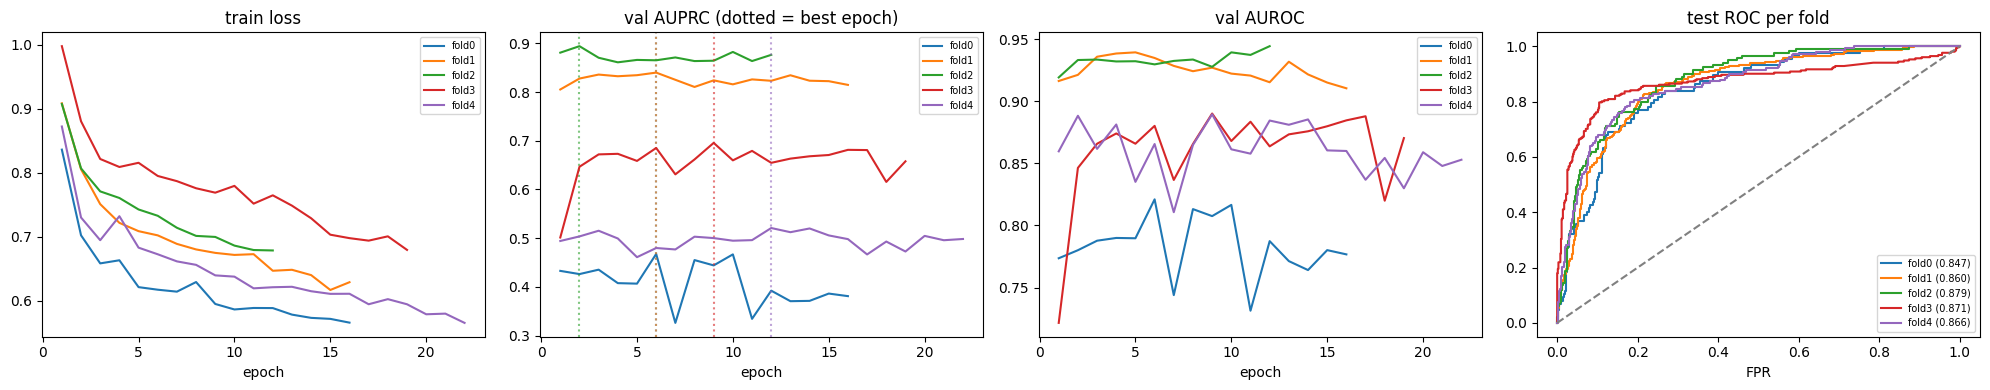

In [10]:
cmap = plt.cm.tab10; fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for k, h in histories.items():
    ax[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], c=cmap(k), label=f"fold{k}")
    ax[1].plot(range(1, len(h["val_auprc"]) + 1), h["val_auprc"], c=cmap(k), label=f"fold{k}"); ax[1].axvline(h["best_epoch"], c=cmap(k), ls=":", alpha=.6)
    ax[2].plot(range(1, len(h["val_auroc"]) + 1), h["val_auroc"], c=cmap(k), label=f"fold{k}")
    m = fold_id == k
    if len(set(y[m])) == 2:
        fpr, tpr, _ = roc_curve(y[m], p_cnn[m]); ax[3].plot(fpr, tpr, c=cmap(k), label=f"fold{k} ({roc_auc_score(y[m], p_cnn[m]):.3f})")
ax[0].set_title("train loss"); ax[1].set_title("val AUPRC (dotted = best epoch)"); ax[2].set_title("val AUROC"); ax[3].set_title("test ROC per fold"); ax[3].plot([0, 1], [0, 1], "--", c="gray")
for a_ in ax: a_.set_xlabel("epoch" if a_ is not ax[3] else "FPR"); a_.legend(fontsize=7)
show("02_training_curves")

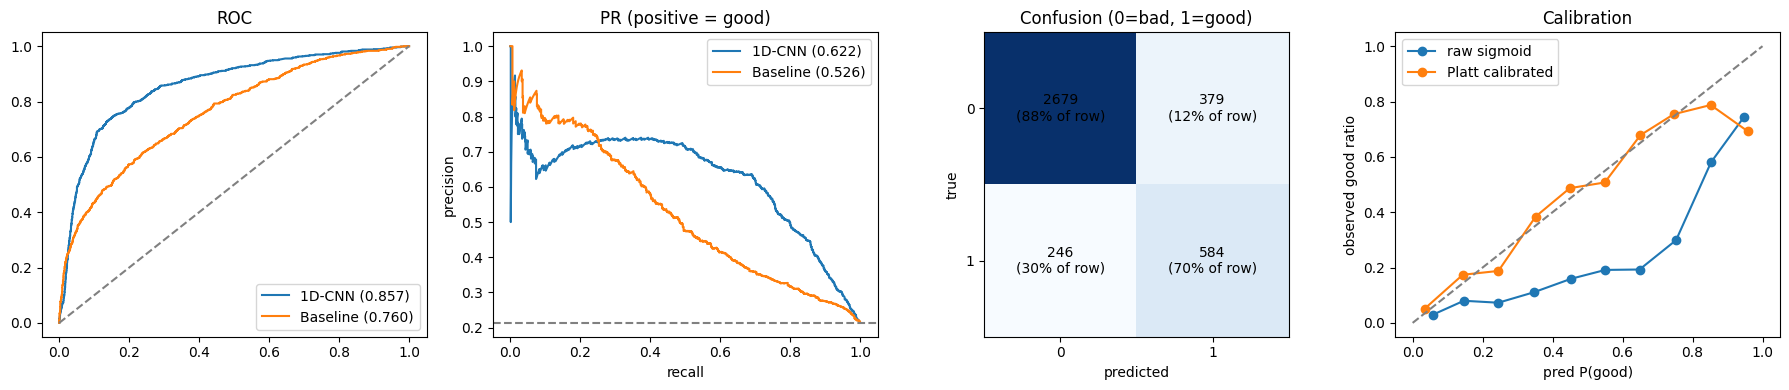

[피험자별 요약] n ≥ 20 인 38명 기준 (n 이 작은 12명은 AUROC 가 의미 없어 제외)
          acc   AUROC
count  38.000  38.000
mean    0.842   0.809
std     0.122   0.160
min     0.556   0.258
25%     0.734   0.736
50%     0.883   0.855
75%     0.942   0.923
max     1.000   1.000

[피험자 전체 표 — AUROC 오름차순, small_n=True 는 해석 주의]


,subject,n,good_ratio,acc,AUROC,small_n
0,104,4,0.750,0.250,0.000,True
1,110,4,0.750,0.750,0.000,True
2,115,108,0.130,0.870,0.258,False
3,112,108,0.019,0.963,0.420,False
4,142,108,0.102,0.556,0.481,False
5,145,96,0.146,0.719,0.652,False
6,128,108,0.019,0.963,0.675,False
7,147,108,0.231,0.593,0.676,False
8,129,108,0.028,0.944,0.676,False
9,146,108,0.333,0.657,0.711,False


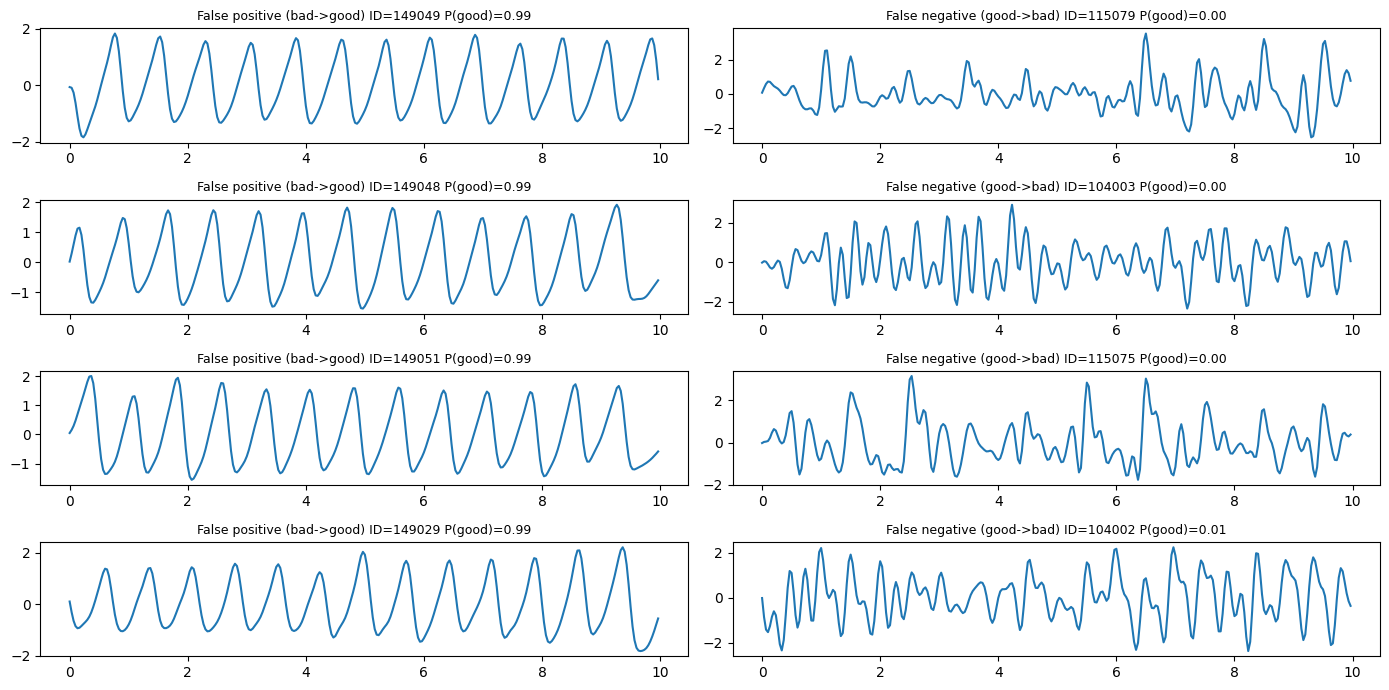

In [11]:
pred = (p_cnn >= thr_cnn).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for name, p in [("1D-CNN", p_cnn), ("Baseline", p_base)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.3f})")
    pr_, rc_, _ = precision_recall_curve(y, p); ax[1].plot(rc_, pr_, label=f"{name} ({average_precision_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set_title("ROC"); ax[0].legend()
ax[1].axhline(y.mean(), ls="--", c="gray"); ax[1].set_title("PR (positive = good)"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend()
cm = confusion_matrix(y, pred, labels=[0, 1]); ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("Confusion (0=bad, 1=good)")
for i in range(2):
    for j in range(2): ax[2].text(j, i, f"{cm[i, j]}\n({cm[i, j]/cm[i].sum():.0%} of row)", ha="center", va="center", color="black")
ax[2].set_xticks([0, 1]); ax[2].set_yticks([0, 1]); ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
def calib(p):
    bi = np.clip((p * 10).astype(int), 0, 9); ok = [c for c in range(10) if (bi == c).sum() > 5]
    return [p[bi == c].mean() for c in ok], [y[bi == c].mean() for c in ok]
for lab, p in [("raw sigmoid", p_raw), ("Platt calibrated", p_cnn)]:
    xs, ys_ = calib(p); ax[3].plot(xs, ys_, "o-", label=lab)
ax[3].plot([0, 1], [0, 1], "--", c="gray"); ax[3].set_title("Calibration"); ax[3].set_xlabel("pred P(good)"); ax[3].set_ylabel("observed good ratio"); ax[3].legend()
show("03_eval_curves")

# 피험자별 성능 — 생략 없이 전부 출력
rows = []
for s_ in sorted(set(groups)):
    m = groups == s_
    rows.append({"subject": s_, "n": int(m.sum()), "good_ratio": y[m].mean(), "acc": accuracy_score(y[m], pred[m]),
                 "AUROC": roc_auc_score(y[m], p_cnn[m]) if len(set(y[m])) > 1 else np.nan, "small_n": int(m.sum()) < MIN_N_SUBJ_METRIC})
subj = pd.DataFrame(rows)
big = subj[~subj.small_n]
print(f"[피험자별 요약] n ≥ {MIN_N_SUBJ_METRIC} 인 {len(big)}명 기준 (n 이 작은 {int(subj.small_n.sum())}명은 AUROC 가 의미 없어 제외)")
print(big[["acc", "AUROC"]].describe().round(3))
print("\n[피험자 전체 표 — AUROC 오름차순, small_n=True 는 해석 주의]"); display(subj.sort_values("AUROC").round(3).reset_index(drop=True))

# 가장 확신하며 틀린 예시: 거짓 양성(나쁜데 좋다고) / 거짓 음성(좋은데 나쁘다고) 각 4개
fp_i = np.where((y == 0) & (pred == 1))[0]; fp_i = fp_i[np.argsort(-p_cnn[fp_i])][:4]
fn_i = np.where((y == 1) & (pred == 0))[0]; fn_i = fn_i[np.argsort(p_cnn[fn_i])][:4]
fig, axes = plt.subplots(4, 2, figsize=(14, 7), squeeze=False)
for c, (ids, title) in enumerate([(fp_i, "False positive (bad->good)"), (fn_i, "False negative (good->bad)")]):
    for r, i in enumerate(ids):
        axes[r, c].plot(t, X[i, 0]); axes[r, c].set_title(f"{title} ID={data['ID'][i]} P(good)={p_cnn[i]:.2f}", fontsize=9)
    for r in range(len(ids), 4): axes[r, c].axis("off")
show("04_confident_errors")

### 6-3. 그룹별 성능 (복원 헤더 / 평평한 신호)
복원 헤더 48개가 따로 놀거나, 평평한 신호만 맞혀서 점수가 오르는지 확인합니다.

In [12]:
rows = []
for name, m in [("전체", np.ones(len(y), bool)), ("정상 헤더 (hdr_fixed=0)", hdr == 0), ("복원 헤더 (hdr_fixed=1)", hdr == 1),
                ("평평한 신호", flat), ("평평하지 않은 신호", ~flat)]:
    if m.sum() == 0: continue
    r = metrics(y[m], p_cnn[m], thr_cnn[m]); rb = metrics(y[m], p_base[m], thr_base[m])
    rows.append({"group": name, "n": int(m.sum()), "good_ratio": y[m].mean(), "CNN AUROC": r["AUROC"], "CNN AUPRC": r["AUPRC"], "CNN Acc": r["Acc"],
                 "CNN Recall(good)": r["Recall(good)"], "CNN Specificity": r["Specificity(bad 걸러냄)"], "Base AUROC": rb["AUROC"], "Base Acc": rb["Acc"]})
grp = pd.DataFrame(rows).set_index("group"); display(grp.round(3))
if flat.any():
    print(f"평평한 신호 {int(flat.sum())}개: CNN 평균 P(good)={p_cnn[flat].mean():.3f}, '좋음'으로 예측된 수={int((pred[flat]==1).sum())}")
    print(f"평평하지 않은 신호만으로 본 '항상 나쁨' 정확도 = {(y[~flat]==0).mean():.3f}  → 위 표의 CNN Acc 와 비교")

,n,good_ratio,CNN AUROC,CNN AUPRC,CNN Acc,CNN Recall(good),CNN Specificity,Base AUROC,Base Acc
group,,,,,,,,,
전체,3888,0.213,0.857,0.622,0.839,0.704,0.876,0.760,0.768
정상 헤더 (hdr_fixed=0),3840,0.207,0.858,0.613,0.839,0.698,0.876,0.752,0.766
복원 헤더 (hdr_fixed=1),48,0.729,0.875,0.958,0.854,0.829,0.923,0.908,0.938
평평한 신호,122,0.025,0.731,0.052,0.975,0.000,1.000,0.095,0.975
평평하지 않은 신호,3766,0.220,0.855,0.623,0.835,0.706,0.871,0.753,0.762


평평한 신호 122개: CNN 평균 P(good)=0.020, '좋음'으로 예측된 수=0
평평하지 않은 신호만으로 본 '항상 나쁨' 정확도 = 0.780  → 위 표의 CNN Acc 와 비교


## 7. 최종 모델 학습 · 저장 · 추론 예시
- 임계값은 최종 모델의 작은 val 이 아니라 **5-fold 임계값 중앙값**을 사용합니다. (두 값 모두 출력)
- 확률 보정(Platt)의 기울기·절편도 `config.json` 에 저장합니다.
- CV 로 성능을 확인한 뒤, **전체 피험자**로 최종 모델을 학습합니다. (피험자 약 15%를 val 로 분리 → early stopping·임계값)
- 저장 위치: `models/but_quality_cnn_v1/` (스모크는 `..._smoke/`) — `best_model.pt`, `config.json`, `metrics.json`, `split.json`, `history.json`, `oof_predictions.csv`, `fold{k}.pt`, `tables/*.csv`, `figures/*.png`
- 이 폴더는 `.gitignore` 대상이 아니므로 커밋하려면 용량(작음)과 라이선스를 확인하세요. `data/raw`·`data/processed` 는 커밋되지 않습니다.

In [13]:
tr_f, va_f = split_train_val(np.arange(len(y)), 7, SEED)
final_model, final_hist = train_one(tr_f, va_f, "[final]")
lg_va = predict_logit(final_model, va_f); final_cal = fit_platt(lg_va, y[va_f])
thr_val = best_threshold(y[va_f], apply_platt(final_cal, lg_va))
thr_cv_med = float(np.median([thr_cnn[fold_id == k][0] for k in range(n_folds)]))
final_thr = thr_cv_med
print(f"최종 val(F1 최대) 임계값: {thr_val:.3f} | CV fold 임계값: {[round(float(thr_cnn[fold_id == k][0]), 3) for k in range(n_folds)]} → 중앙값 {thr_cv_med:.3f}  ← 최종 사용")
cmp = pd.DataFrame({f"CV 중앙값 {thr_cv_med:.3f}": metrics(y, p_cnn, np.full(len(y), thr_cv_med)), f"final-val {thr_val:.3f}": metrics(y, p_cnn, np.full(len(y), thr_val))})
print("[OOF 예측에 두 임계값을 똑같이 적용한 비교]"); display(cmp.loc[["Precision(good)", "Recall(good)", "F1(good)", "BalAcc", "MCC"]].round(4))

os.makedirs(RESULT_DIR, exist_ok=True); os.makedirs(f"{RESULT_DIR}/tables", exist_ok=True)
torch.save(final_model.state_dict(), f"{RESULT_DIR}/best_model.pt")
for k, st in fold_states.items(): torch.save(st, f"{RESULT_DIR}/fold{k}.pt")
config = {"task": "BUT PPG quality (1=good for HR, 0=bad)", "dataset": "but (PhysioNet butppg 2.0.0)", "fs": FS, "n_samples": N_SAMPLES,
          "channel": CHANNEL_NAME, "bandpass_hz": [0.5, 5.0], "normalize": "per-sample z-score (flat signal std<%g -> zeros)" % FLAT_STD,
          "threshold": final_thr, "threshold_final_val": thr_val, "threshold_cv_median": thr_cv_med,
          "platt": {"slope": float(final_cal.coef_[0, 0]), "intercept": float(final_cal.intercept_[0]), "note": "p_good = sigmoid(slope*logit + intercept)"},
          "model": "PPGQualityCNN(3 blocks, 16-32-64)", "epochs_max": EPOCHS, "batch": BATCH, "lr": LR, "seed": SEED,
          "n_samples_total": int(len(y)), "n_subjects": int(len(set(groups))), "n_header_fixed": int(data["hdr_fixed"].sum()),
          "exclude_hdr_fixed": EXCLUDE_HDR_FIXED, "smoke_test": SMOKE_TEST}
json.dump(config, open(f"{RESULT_DIR}/config.json", "w"), indent=2, ensure_ascii=False)
json.dump({"pooled_oof": summary.to_dict(), "per_fold_cnn": cv.round(4).to_dict(orient="index"), "per_fold_baseline": cv_base.round(4).to_dict(orient="index"),
           "fold_mean_std": fold_agg.reset_index().to_dict(orient="records"),
           "bootstrap_ci": ci.to_dict(orient="index"), "groups": grp.round(4).to_dict(orient="index")}, open(f"{RESULT_DIR}/metrics.json", "w"), indent=2, ensure_ascii=False)
json.dump(split_info, open(f"{RESULT_DIR}/split.json", "w"), indent=2)
json.dump({"folds": histories, "final": final_hist}, open(f"{RESULT_DIR}/history.json", "w"), indent=2)
pd.DataFrame({"ID": data["ID"], "subject": groups, "hdr_fixed": hdr, "y": y, "p_cnn_raw": p_raw, "p_cnn": p_cnn, "p_base": p_base,
              "thr_cnn": thr_cnn, "thr_base": thr_base, "pred_cnn": pred, "fold": fold_id}).to_csv(f"{RESULT_DIR}/oof_predictions.csv", index=False)
for name, df_ in [("summary", summary), ("fold_table", fold_table), ("per_fold_cnn", cv), ("per_fold_baseline", cv_base), ("bootstrap_ci", ci),
                  ("threshold_sensitivity", thr_table), ("subject_metrics", subj), ("group_metrics", grp)]:
    df_.to_csv(f"{RESULT_DIR}/tables/{name}.csv", encoding="utf-8-sig")
print("저장 완료:", RESULT_DIR)

[final] ep01 loss=0.8548 val_AUPRC=0.7083 val_AUROC=0.9131 lr=1.0e-03  *best
[final] ep02 loss=0.7515 val_AUPRC=0.7195 val_AUROC=0.9370 lr=1.0e-03  *best
[final] ep03 loss=0.7321 val_AUPRC=0.7707 val_AUROC=0.9325 lr=1.0e-03  *best
[final] ep04 loss=0.7155 val_AUPRC=0.7611 val_AUROC=0.9355 lr=1.0e-03
[final] ep05 loss=0.6913 val_AUPRC=0.7186 val_AUROC=0.9295 lr=1.0e-03
[final] ep06 loss=0.7023 val_AUPRC=0.7472 val_AUROC=0.9264 lr=1.0e-03
[final] ep07 loss=0.6833 val_AUPRC=0.7554 val_AUROC=0.9363 lr=1.0e-03
[final] ep08 loss=0.6784 val_AUPRC=0.7624 val_AUROC=0.9231 lr=5.0e-04
[final] ep09 loss=0.6557 val_AUPRC=0.6860 val_AUROC=0.9257 lr=5.0e-04
[final] ep10 loss=0.6499 val_AUPRC=0.6953 val_AUROC=0.9115 lr=5.0e-04
[final] ep11 loss=0.6457 val_AUPRC=0.7080 val_AUROC=0.9064 lr=5.0e-04
[final] ep12 loss=0.6471 val_AUPRC=0.7252 val_AUROC=0.8978 lr=5.0e-04
[final] ep13 loss=0.6346 val_AUPRC=0.7189 val_AUROC=0.9291 lr=2.5e-04
[final] epochs=13 (best ep=3) best val AUPRC=0.7707
최종 val(F1 최대) 임계값

,CV 중앙값 0.341,final-val 0.351
Precision(good),0.6275,0.6343
Recall(good),0.6940,0.6916
F1(good),0.6590,0.6617
BalAcc,0.7911,0.7917
MCC,0.5617,0.5656


저장 완료: /content/drive/MyDrive/Colab Notebooks/capdyssey/models/but_quality_cnn_v1


In [14]:
# 새 PPG(30Hz, 300개 값, 빨간 채널 0~255 밝기)에 대한 추론 예시
def predict_quality(ppg_300, model=final_model, cal=final_cal, thr=final_thr):
    x = preprocess(np.asarray(ppg_300, dtype=np.float32))
    with torch.no_grad():
        z = model.eval()(torch.from_numpy(x)[None, None].to(device)).item()
    p = float(apply_platt(cal, [z])[0])
    return {"p_good": round(p, 4), "label": int(p >= thr)}       # 1 = 심박수 읽기 좋은 품질 (보정된 확률)

rng_ = np.random.default_rng(SEED)
pick = list(rng_.choice(np.where(y == 1)[0], 3, replace=False)) + list(rng_.choice(np.where(y == 0)[0], 3, replace=False))
rows = []
for i in pick:
    r = predict_quality(X_raw[i])
    rows.append({"ID": data["ID"][i], "정답": y[i], "final모델 p_good": r["p_good"], "final모델 label": r["label"],
                 "OOF p_good": round(float(p_cnn[i]), 4), "OOF label": int(pred[i])})
print("※ final 모델은 이 샘플들로 학습했으므로 낙관적입니다. 실제 성능에 가까운 값은 'OOF' 열(학습에 쓰이지 않은 fold 모델 예측)입니다.")
display(pd.DataFrame(rows))

※ final 모델은 이 샘플들로 학습했으므로 낙관적입니다. 실제 성능에 가까운 값은 'OOF' 열(학습에 쓰이지 않은 fold 모델 예측)입니다.


,ID,정답,final모델 p_good,final모델 label,OOF p_good,OOF label
0,140009,1,0.9783,1,0.8970,1
1,119013,1,0.6408,1,0.4380,1
2,142099,1,0.3472,1,0.5670,1
3,114099,0,0.0126,0,0.0503,0
4,137049,0,0.0375,0,0.0361,0
5,144045,0,0.0637,0,0.0719,0


## 8. 저장된 결과 전체 보기
폴더 안 파일 목록과 설정, 핵심 표를 한 번에 다시 출력합니다.

In [15]:
print("결과 폴더:", RESULT_DIR)
for root, _, fs_ in sorted(os.walk(RESULT_DIR)):
    for f in sorted(fs_): print(f"  {os.path.relpath(os.path.join(root, f), RESULT_DIR):40s} {os.path.getsize(os.path.join(root, f))/1024:8.1f} KB")
print("\n[config.json]"); print(open(f"{RESULT_DIR}/config.json", encoding="utf-8").read())
print("[전체 OOF 성능]"); display(summary.round(4))
print("[95% CI (피험자 부트스트랩)]"); display(ci)
print("[fold 상세]"); display(fold_table.round(4))
print("[그룹별]"); display(grp.round(3))
print("[임계값 민감도]"); display(thr_table.round(3))

결과 폴더: /content/drive/MyDrive/Colab Notebooks/capdyssey/models/but_quality_cnn_v1
  best_model.pt                               184.0 KB
  config.json                                   0.8 KB
  fold0.pt                                    179.2 KB
  fold1.pt                                    179.2 KB
  fold2.pt                                    179.2 KB
  fold3.pt                                    179.2 KB
  fold4.pt                                    179.2 KB
  history.json                                 10.7 KB
  metrics.json                                  8.4 KB
  oof_predictions.csv                         442.7 KB
  split.json                                    3.7 KB
  figures/01_examples.png                     203.7 KB
  figures/02_training_curves.png              200.3 KB
  figures/03_eval_curves.png                  136.0 KB
  figures/04_confident_errors.png             318.1 KB
  tables/bootstrap_ci.csv                       0.5 KB
  tables/fold_table.csv               

,1D-CNN,Baseline(LogReg+진폭)
AUROC,0.8575,0.7601
AUPRC,0.6219,0.5259
Acc,0.8392,0.7683
BalAcc,0.7898,0.6714
Precision(good),0.6064,0.4608
Recall(good),0.7036,0.5024
F1(good),0.6514,0.4807
Specificity(bad 걸러냄),0.8761,0.8404
MCC,0.5503,0.3324
Brier,0.1128,0.1381


[95% CI (피험자 부트스트랩)]


,point,ci_2.5%,ci_97.5%
CNN AUROC,0.8575,0.8153,0.8913
CNN AUPRC,0.6219,0.4765,0.7531
CNN BalAcc,0.7898,0.7389,0.8300
CNN F1(good),0.6514,0.5530,0.7275
CNN MCC,0.5503,0.4510,0.6318
Base AUROC,0.7601,0.7128,0.8014
Base AUPRC,0.5259,0.3758,0.6514
Base BalAcc,0.6714,0.6280,0.7102
Base F1(good),0.4807,0.3802,0.5688
Base MCC,0.3324,0.2392,0.4154


[fold 상세]


,n_train,n_val,n_test,test_subjects,val_good,test_good,epochs_run,best_epoch,val_AUPRC(raw),thr_cnn,thr_base,platt_slope,platt_intercept
fold,,,,,,,,,,,,,
0,2742,648,498,8,0.1775,0.1747,16,6,0.4676,0.3248,0.3759,0.7488,-1.5778
1,2538,278,1072,12,0.1906,0.2099,16,6,0.8400,0.5062,0.2782,1.3122,-0.5054
2,2862,440,586,7,0.2818,0.2014,12,2,0.8943,0.4345,0.3242,2.0897,-2.3653
3,2156,848,884,13,0.2618,0.2839,19,9,0.6957,0.3411,0.4039,1.1076,-2.1961
4,2442,598,848,10,0.1204,0.1757,22,12,0.5208,0.1478,0.1598,0.8751,-1.4692


[그룹별]


,n,good_ratio,CNN AUROC,CNN AUPRC,CNN Acc,CNN Recall(good),CNN Specificity,Base AUROC,Base Acc
group,,,,,,,,,
전체,3888,0.213,0.857,0.622,0.839,0.704,0.876,0.760,0.768
정상 헤더 (hdr_fixed=0),3840,0.207,0.858,0.613,0.839,0.698,0.876,0.752,0.766
복원 헤더 (hdr_fixed=1),48,0.729,0.875,0.958,0.854,0.829,0.923,0.908,0.938
평평한 신호,122,0.025,0.731,0.052,0.975,0.000,1.000,0.095,0.975
평평하지 않은 신호,3766,0.220,0.855,0.623,0.835,0.706,0.871,0.753,0.762


[임계값 민감도]


,Precision(good),Recall(good),F1(good),Specificity(bad 걸러냄),BalAcc,MCC,TP,FP,FN,TN
thr,,,,,,,,,,
0.2,0.524,0.765,0.622,0.811,0.788,0.510,635,577,195,2481
0.3,0.602,0.713,0.653,0.872,0.793,0.552,592,391,238,2667
0.4,0.646,0.637,0.642,0.905,0.771,0.545,529,290,301,2768
0.5,0.682,0.548,0.608,0.931,0.739,0.520,455,212,375,2846
0.6,0.726,0.466,0.568,0.952,0.709,0.499,387,146,443,2912
0.7,0.739,0.375,0.497,0.964,0.669,0.447,311,110,519,2948
0.8,0.732,0.264,0.388,0.974,0.619,0.366,219,80,611,2978
